<a href="https://colab.research.google.com/github/mariedb/RNA-seq-psychiatric-disorders/blob/main/Testing_Data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
# Import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# Load the datasets
counts = pd.read_csv("GSE80655_counts.csv")
metadata = pd.read_csv("GSE80655_metadata.csv")

# Display the first five rows
display(counts.head())
display(metadata.head())

,gene_id,SL31501,SL31502,SL31503,SL31504,SL31505,SL31506,SL31507,SL31508,SL32225,...,SL7849,SL7851,SL7852,SL7853,SL7854,SL7855,SL7856,SL7857,SL7858,SL8435
0,ENSG00000223972,0,0,0,0,0,0,0,0,3,...,1,0,0,0,0,2,0,1,1,0
1,ENSG00000227232,93,80,116,50,233,113,119,146,225,...,147,166,118,74,88,194,121,83,418,50
2,ENSG00000243485,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,ENSG00000237613,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,ENSG00000268020,1,0,0,1,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0


,GSM,title,description,brain_region,diagnosis,age,sex,ethnicity,PMI,brain_pH,donor_id
0,GSM2132201,X1834_AnCg_C_SL31501,SL31501,AnCg,Control,40,M,Caucasian,12.25,6.76,1834
1,GSM2132202,X2315_AnCg_M_SL31502,SL31502,AnCg,Major Depression,58,M,Caucasian,24.00,6.93,2315
2,GSM2132203,X2566_AnCg_B_SL31503,SL31503,AnCg,Bipolar Disorder,56,F,Caucasian,29.00,6.83,2566
3,GSM2132204,X3031_AnCg_M_SL31504,SL31504,AnCg,Major Depression,49,M,Caucasian,27.00,7.19,3031
4,GSM2132205,X2353_nAcc_S_SL31505,SL31505,nAcc,Schizophrenia,31,F,Caucasian,22.00,6.77,2353


We first inspect the datasets to understand how the data are organized, identify the columns and check whether the files were imported correctly.

In [16]:
# Check the dimensions of both datasets
print("Counts dataset:", counts.shape)
print("Metadata dataset:", metadata.shape)

Counts dataset: (57905, 282)
Metadata dataset: (281, 11)


In [17]:
# Inspect the structure of the datasets
print("COUNTS DATASET")
counts.info()

print("\nMETADATA DATASET")
metadata.info()

COUNTS DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57905 entries, 0 to 57904
Columns: 282 entries, gene_id to SL8435
dtypes: int64(281), object(1)
memory usage: 124.6+ MB

METADATA DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 281 entries, 0 to 280
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   GSM           281 non-null    object 
 1   title         281 non-null    object 
 2   description   281 non-null    object 
 3   brain_region  281 non-null    object 
 4   diagnosis     281 non-null    object 
 5   age           281 non-null    int64  
 6   sex           281 non-null    object 
 7   ethnicity     281 non-null    object 
 8   PMI           281 non-null    float64
 9   brain_pH      278 non-null    float64
 10  donor_id      281 non-null    int64  
dtypes: float64(2), int64(2), object(7)
memory usage: 24.3+ KB


We need to distinguish between numerical RNA-seq counts and categorical or numerical metadata variables. This is important because different variable types require different preprocessing and statistical methods.

In [18]:
# Descriptive statistics of the metadata
display(metadata.describe(include="all"))

# Descriptive statistics of the RNA-seq counts
display(counts.iloc[:, 1:].describe())

,GSM,title,description,brain_region,diagnosis,age,sex,ethnicity,PMI,brain_pH,donor_id
count,281,281,281,281,281,281.000000,281,281,281.000000,278.000000,281.000000
unique,281,281,281,3,4,NaN,2,5,NaN,NaN,NaN
top,GSM2132201,X1834_AnCg_C_SL31501,SL31501,AnCg,Schizophrenia,NaN,M,Caucasian,NaN,NaN,NaN
freq,1,1,1,96,71,NaN,222,260,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,46.743772,NaN,NaN,22.667794,6.901475,3493.729537
std,NaN,NaN,NaN,NaN,NaN,12.707078,NaN,NaN,7.659093,0.178183,699.543605
min,NaN,NaN,NaN,NaN,NaN,19.000000,NaN,NaN,6.250000,6.520000,1834.000000
25%,NaN,NaN,NaN,NaN,NaN,39.000000,NaN,NaN,17.200000,6.770000,3031.000000
50%,NaN,NaN,NaN,NaN,NaN,48.000000,NaN,NaN,24.000000,6.900000,3572.000000
75%,NaN,NaN,NaN,NaN,NaN,55.000000,NaN,NaN,27.500000,7.037500,4046.000000


,SL31501,SL31502,SL31503,SL31504,SL31505,SL31506,SL31507,SL31508,SL32225,SL32226,...,SL7849,SL7851,SL7852,SL7853,SL7854,SL7855,SL7856,SL7857,SL7858,SL8435
count,57905.000000,57905.000000,57905.000000,57905.000000,5.790500e+04,57905.000000,5.790500e+04,5.790500e+04,5.790500e+04,57905.000000,...,5.790500e+04,5.790500e+04,5.790500e+04,5.790500e+04,5.790500e+04,5.790500e+04,5.790500e+04,5.790500e+04,5.790500e+04,5.790500e+04
mean,437.695847,464.709524,485.617719,347.475227,5.680729e+02,524.043071,5.123534e+02,5.410858e+02,6.878818e+02,692.521596,...,6.012063e+02,6.796152e+02,6.880296e+02,5.305588e+02,4.909466e+02,5.277926e+02,4.256702e+02,6.444194e+02,1.008203e+03,7.112878e+02
std,4871.966784,4395.033374,5057.786315,5606.635657,1.024478e+04,7215.864885,8.713979e+03,8.351686e+03,8.676116e+03,6617.480748,...,1.056473e+04,1.327111e+04,1.593522e+04,1.146001e+04,1.326196e+04,1.319027e+04,1.236398e+04,3.483129e+04,1.894487e+04,1.284344e+04
min,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,...,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
50%,2.000000,1.000000,1.000000,1.000000,2.000000e+00,2.000000,2.000000e+00,2.000000e+00,2.000000e+00,2.000000,...,4.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,4.000000e+00,3.000000e+00,4.000000e+00,6.000000e+00,6.000000e+00,1.000000e+00
75%,52.000000,46.000000,47.000000,32.000000,6.400000e+01,56.000000,6.500000e+01,5.900000e+01,7.300000e+01,71.000000,...,7.300000e+01,8.100000e+01,7.800000e+01,6.400000e+01,7.800000e+01,7.200000e+01,6.600000e+01,7.000000e+01,1.490000e+02,5.300000e+01
max,663779.000000,498867.000000,624515.000000,696293.000000,1.313874e+06,903633.000000,1.207358e+06,1.073688e+06,1.221797e+06,760401.000000,...,1.389999e+06,1.946562e+06,2.490982e+06,1.655896e+06,1.926009e+06,1.984185e+06,1.608868e+06,5.490664e+06,2.717298e+06,1.749535e+06


This provides an initial overview of the distribution of the variables and helps identify unusual values or potential data quality issues.

2.1 Check missing values


> Missing values can affect statistical analyses and machine learning models. We first identify their location and frequency before deciding whether they need to be handled.



In [19]:
# Check the number of missing values per column

print("Missing values in counts:")
print(counts.isnull().sum().sum())

print("\nMissing values in metadata:")
print(metadata.isnull().sum())

Missing values in counts:
0

Missing values in metadata:
GSM             0
title           0
description     0
brain_region    0
diagnosis       0
age             0
sex             0
ethnicity       0
PMI             0
brain_pH        3
donor_id        0
dtype: int64


2.2 Check duplicate identifiers

> Duplicated gene or sample identifiers can cause problems when matching the count matrix with the metadata. We also examine donor IDs because multiple samples may originate from the same individual.



In [20]:
# Check for duplicated gene identifiers
print("Duplicated gene IDs:", counts["gene_id"].duplicated().sum())

# Check for duplicated sample identifiers
print("Duplicated sample descriptions:", metadata["description"].duplicated().sum())

# Check for duplicated donor IDs
print("Number of unique donors:", metadata["donor_id"].nunique())
print("Number of samples:", len(metadata))

Duplicated gene IDs: 0
Duplicated sample descriptions: 0
Number of unique donors: 96
Number of samples: 281


2.3 Check whether the sample IDs match

> The count matrix and metadata must refer to exactly the same samples. Correct sample matching is essential to ensure that gene expression measurements are associated with the correct diagnosis, brain region and donor information.



In [21]:
# Extract sample IDs from the counts dataset
count_sample_ids = counts.columns[1:]

# Extract sample IDs from the metadata
metadata_sample_ids = metadata["description"]

# Check whether the sample IDs match in the same order
print("Sample IDs match:", list(count_sample_ids) == list(metadata_sample_ids))

Sample IDs match: True


2.4 Check the validity of the raw counts

> Raw RNA-seq counts represent the number of sequencing reads assigned to each gene. Therefore, they should be non-negative integer values. Negative or non-integer values could indicate an import or data processing problem.



In [22]:
# Extract the numerical count data
count_values = counts.iloc[:, 1:]

# Check for negative values
print("Negative values:", (count_values < 0).sum().sum())

# Check for non-integer values
print(
    "Non-integer values:",
    (count_values % 1 != 0).sum().sum()
)

Negative values: 0
Non-integer values: 0


## **Step 3 – Explore sample quality and count distributions**

3.1 Investigate the missing brain pH values

> This step identifies the samples with missing brain pH measurements. By examining their diagnosis, brain region and donor information, we can determine whether the missing values are concentrated in a particular subgroup.



In [23]:
# Identify samples with missing brain pH values

missing_ph = metadata[metadata["brain_pH"].isnull()]

display(
    missing_ph[["description", "diagnosis", "brain_region",
                "age", "sex", "donor_id"]]
)

,description,diagnosis,brain_region,age,sex,donor_id
126,SL6616,Schizophrenia,AnCg,31,M,4463
198,SL7390,Schizophrenia,nAcc,31,M,4463
256,SL7802,Schizophrenia,DLPFC,31,M,4463


3.2 Calculate the library size of each sample


> Library size represents the total number of sequencing reads assigned to genes in a sample. Differences in library size can influence observed gene expression counts. Samples with substantially lower or higher library sizes may require further investigation before downstream analysis.



In [24]:
# Calculate the total number of reads per sample

library_sizes = counts.iloc[:, 1:].sum(axis=0)

# Create a dataframe containing library sizes and sample information
library_size_df = pd.DataFrame({
    "description": counts.columns[1:],
    "library_size": library_sizes.values
})

# Add metadata
library_size_df = library_size_df.merge(
    metadata,
    on="description"
)

# Display descriptive statistics
display(library_size_df["library_size"].describe())

,library_size
count,2.810000e+02
mean,4.208535e+07
std,1.272908e+07
min,1.168605e+07
25%,3.322680e+07
50%,4.086196e+07
75%,5.075643e+07
max,7.319786e+07


3.3 Visualize the library size distribution

>The histogram shows the distribution of total read counts across samples. It helps identify whether most samples have comparable sequencing depths and whether some samples have unusually low or high library sizes.



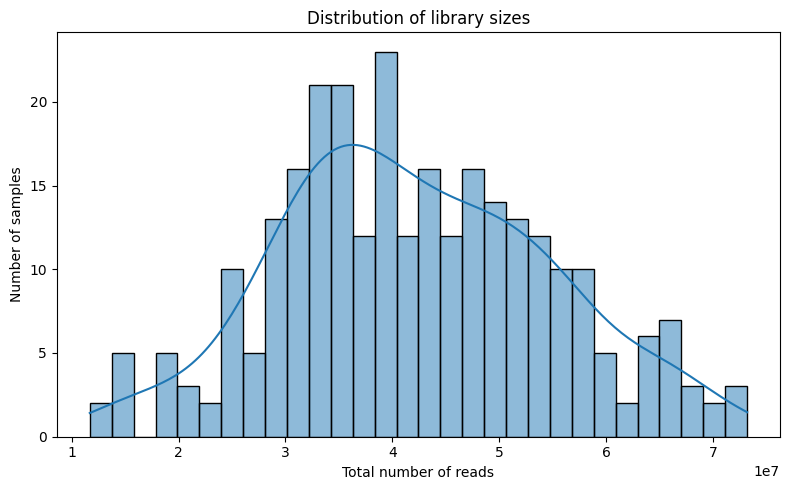

In [25]:
# Visualize the distribution of library sizes

plt.figure(figsize=(8, 5))

sns.histplot(
    data=library_size_df,
    x="library_size",
    bins=30,
    kde=True
)

plt.title("Distribution of library sizes")
plt.xlabel("Total number of reads")
plt.ylabel("Number of samples")

plt.tight_layout()
plt.show()

3.4 Compare library sizes between diagnostic groups

> This boxplot compares sequencing depth between diagnostic groups. If one group consistently has higher or lower library sizes, this may indicate a technical difference that should be considered during preprocessing. However, differences in library size do not automatically indicate poor sample quality.



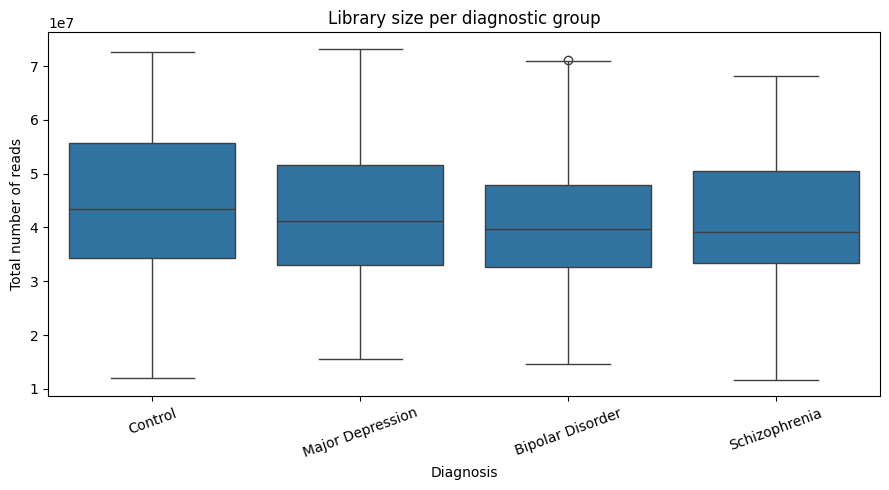

In [26]:
# Compare library sizes between diagnostic groups

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=library_size_df,
    x="diagnosis",
    y="library_size"
)

plt.title("Library size per diagnostic group")
plt.xlabel("Diagnosis")
plt.ylabel("Total number of reads")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## **Step 4 – Preprocessing of the RNA-seq data**

4.1 Prepare the count matrix

> The gene identifiers are converted into row indices so that each row represents one gene and each column represents one sample. This creates a numerical expression matrix that can be used for filtering, normalization and further analysis.



In [27]:
# Set gene IDs as the index
count_matrix = counts.set_index("gene_id")

# Check the dimensions
print("Count matrix dimensions:", count_matrix.shape)

# Display the first five rows
display(count_matrix.head())

Count matrix dimensions: (57905, 281)


,SL31501,SL31502,SL31503,SL31504,SL31505,SL31506,SL31507,SL31508,SL32225,SL32226,...,SL7849,SL7851,SL7852,SL7853,SL7854,SL7855,SL7856,SL7857,SL7858,SL8435
gene_id,,,,,,,,,,,,,,,,,,,,,
ENSG00000223972,0,0,0,0,0,0,0,0,3,0,...,1,0,0,0,0,2,0,1,1,0
ENSG00000227232,93,80,116,50,233,113,119,146,225,156,...,147,166,118,74,88,194,121,83,418,50
ENSG00000243485,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ENSG00000237613,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ENSG00000268020,1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0


4.2 Check the number of genes with zero counts

> Genes with zero counts across all samples provide no information for downstream differential expression analysis. Genes with very low expression may also contribute little statistical power. Therefore, we first investigate the expression distribution before deciding whether to remove lowly expressed genes.



In [28]:
# Calculate the total number of reads per gene across all samples
gene_counts = count_matrix.sum(axis=1)

# Count genes with zero reads across all samples
zero_count_genes = (gene_counts == 0).sum()

# Count genes with at least one read
expressed_genes = (gene_counts > 0).sum()

print("Total number of genes:", len(count_matrix))
print("Genes with zero counts:", zero_count_genes)
print("Genes with at least one read:", expressed_genes)

Total number of genes: 57905
Genes with zero counts: 1985
Genes with at least one read: 55920


4.3 Investigate lowly expressed genes

> A gene can have non-zero counts but still be expressed at a very low level. Such genes may provide limited information for downstream statistical analyses. Therefore, we investigate how many samples show detectable expression for each gene before deciding on an appropriate filtering strategy.



In [29]:
# Count the number of samples in which each gene has at least one read
detected_samples = (count_matrix > 0).sum(axis=1)

# Summarize the number of samples in which genes are detected
print("Number of samples in which genes are detected:")
print(detected_samples.describe())

# Count genes detected in different numbers of samples
print("\nGenes detected in fewer than 5 samples:",
      (detected_samples < 5).sum())

print("Genes detected in at least 5 samples:",
      (detected_samples >= 5).sum())

print("Genes detected in at least 10 samples:",
      (detected_samples >= 10).sum())

Number of samples in which genes are detected:
count    57905.000000
mean       185.079820
std        104.122545
min          0.000000
25%         79.000000
50%        237.000000
75%        281.000000
max        281.000000
dtype: float64

Genes detected in fewer than 5 samples: 2612
Genes detected in at least 5 samples: 55293
Genes detected in at least 10 samples: 54656


4.4 – Visualize the distribution of detected genes

> A histogram is used to visualize the distribution of the number of samples in which genes are detected. This allows us to assess whether most genes are detected across many samples or whether a substantial number of genes are only detected in a small number of samples.



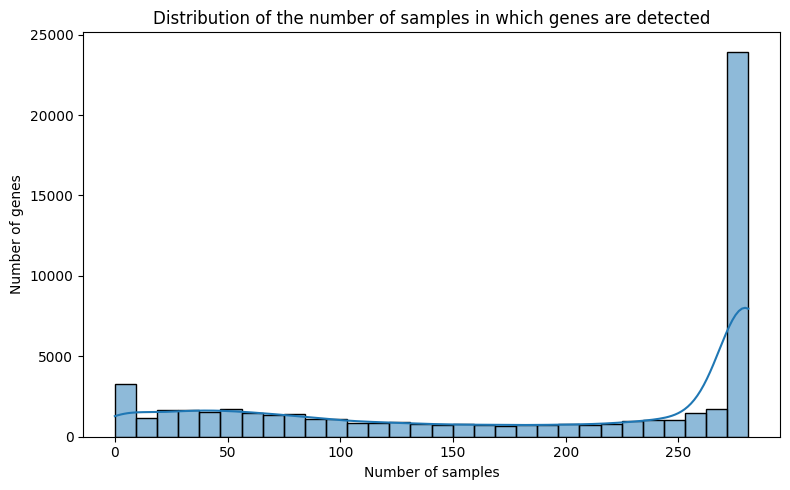

In [30]:
# Visualize the distribution of detected samples per gene

plt.figure(figsize=(8, 5))

sns.histplot(
    detected_samples,
    bins=30,
    kde=True
)

plt.title("Distribution of the number of samples in which genes are detected")
plt.xlabel("Number of samples")
plt.ylabel("Number of genes")

plt.tight_layout()
plt.show()

We can identify three important observations:
1. Large peak at 281 samples: A substantial number of genes are detected in all 281 samples. These genes are consistently expressed across the dataset.
2. Wide distribution: Other genes are detected in fewer samples, indicating considerable variation in gene detection across samples.
3. Genes detected in very few or zero samples: There is a group of genes with very limited detection. These genes may be candidates for filtering.


The histogram shows a non-uniform distribution of gene detection across samples. A large proportion of genes are detected in all 281 samples, as indicated by the prominent peak at the right side of the histogram. However, a considerable number of genes are detected in fewer samples, including genes with zero or very limited detection. This suggests that some genes may have very low expression and could be considered for filtering before downstream analysis.

4.5 – Investigate expression levels using CPM

> Counts Per Million (CPM) accounts for differences in sequencing depth between samples by expressing gene counts relative to the total number of reads in each sample. This allows gene expression levels to be compared more fairly across samples.



In [31]:
# Calculate the library size for each sample
library_sizes = count_matrix.sum(axis=0)

# Calculate Counts Per Million (CPM)
cpm_matrix = count_matrix.div(library_sizes, axis=1) * 1_000_000

# Display the first five rows
display(cpm_matrix.head())

,SL31501,SL31502,SL31503,SL31504,SL31505,SL31506,SL31507,SL31508,SL32225,SL32226,...,SL7849,SL7851,SL7852,SL7853,SL7854,SL7855,SL7856,SL7857,SL7858,SL8435
gene_id,,,,,,,,,,,,,,,,,,,,,
ENSG00000223972,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.075317,0.000000,...,0.028725,0.000000,0.000000,0.000000,0.000000,0.065441,0.000000,0.026799,0.017129,0.000000
ENSG00000227232,3.669395,2.972982,4.125223,2.485021,7.083303,3.723878,4.01108,4.659836,5.648754,3.890229,...,4.222579,4.218217,2.961821,2.408697,3.095511,6.347787,4.909034,2.224300,7.159988,1.213972
ENSG00000243485,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000237613,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000268020,0.039456,0.000000,0.000000,0.049700,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.070353,0.000000,0.000000,0.000000,0.000000,0.000000


4.6 Visualize the CPM distribution across samples

> After calculating the Counts Per Million (CPM) values in step 4.5, we want to investigate how gene expression is distributed across the different samples.

Visualizing the distributions allows us to:
- Check whether samples have comparable gene expression distributions.
- Identify samples with unusually high or low expression values.
- Detect potential differences in sample quality or sequencing characteristics.
- Evaluate whether normalization may be needed before downstream analyses.
Because CPM values are often highly skewed, we first apply a log2 transformation. This makes the distributions easier to visualize and compare.

We expect the samples to have relatively comparable distributions. If some samples show substantially different distributions, this could indicate technical differences or potential sample-quality issues that require further investigation.

Importantly, differences in expression distributions do not automatically mean that a sample is of poor quality.

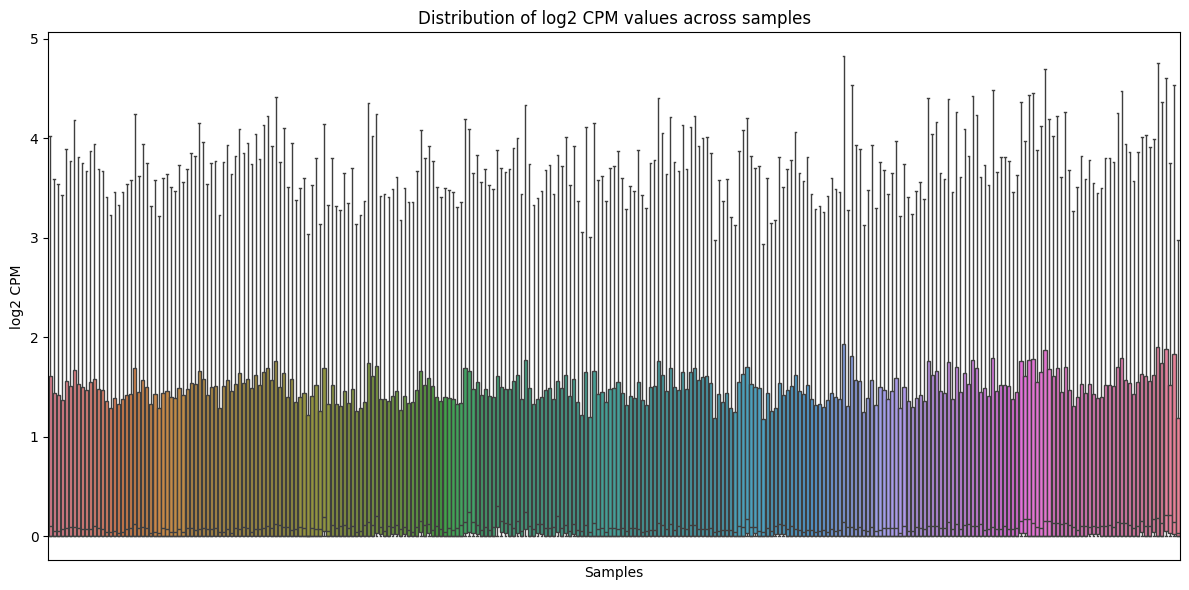

In [32]:
# Calculate log2 CPM values
log_cpm_matrix = np.log2(cpm_matrix + 1)

# Visualize the distribution across samples
plt.figure(figsize=(12, 6))

sns.boxplot(data=log_cpm_matrix, showfliers=False)

plt.title("Distribution of log2 CPM values across samples")
plt.xlabel("Samples")
plt.ylabel("log2 CPM")

plt.xticks([])
plt.tight_layout()
plt.show()

The plot does not reveal an obvious extreme outlier sample based on the overall expression distribution. Nevertheless, differences between samples should be considered during normalization and subsequent analyses.

Important: CPM corrects for differences in library size, but it does not account for all differences in RNA composition. We will therefore still need an appropriate normalization procedure, such as TMM normalization using edgeR, in the RNA-seq preprocessing workflow.

4.7 Filter lowly expressed genes

> Genes with very low expression across almost all samples provide little reliable information for downstream statistical analysis. Including these genes can increase the number of statistical tests and reduce statistical power.

We therefore remove genes that do not reach a sufficient expression level in enough samples.

Filtering criterion: A gene must have at least 10 CPM (Counts Per Million) in at least 5 samples to be retained.


In [34]:
# Identify genes with at least 10 CPM in at least 5 samples
keep = (cpm_matrix >= 10).sum(axis=1) >= 5

# Filter the count matrix
filtered_count_matrix = count_matrix.loc[keep, :]

# Also filter the CPM matrix
filtered_cpm_matrix = cpm_matrix.loc[keep, :]

# Check the number of genes before and after filtering
print("Genes before filtering:", count_matrix.shape[0])
print("Genes after filtering:", filtered_count_matrix.shape[0])
print("Genes removed:", (~keep).sum())

Genes before filtering: 57905
Genes after filtering: 12296
Genes removed: 45609


4.8 Calculate log2 CPM values after filtering

> We now want to work with the expression values of the retained genes.

CPM (Counts Per Million) accounts for differences in library size between samples. However, expression values are often highly skewed, with a small number of genes having very high expression.

Taking the log2 transformation makes the distribution more manageable and facilitates visualization and comparison between samples.

We add 1 before taking the logarithm to avoid calculating log2(0).



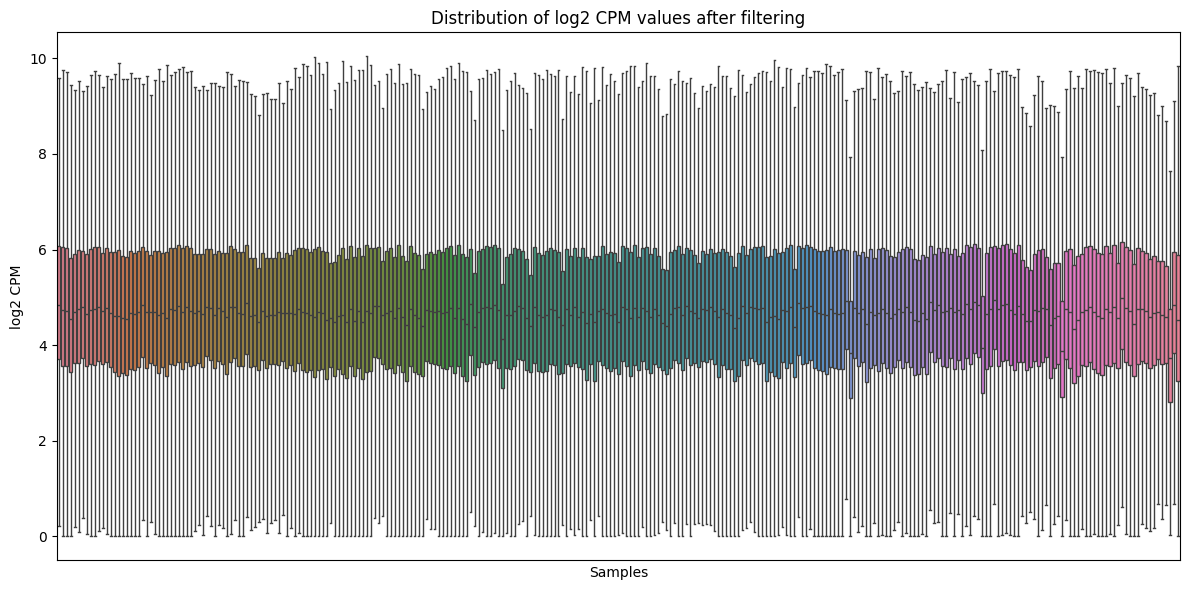

In [35]:
# Calculate log2 CPM values for the filtered genes
filtered_log_cpm_matrix = np.log2(filtered_cpm_matrix + 1)

# Visualize the distribution across samples
plt.figure(figsize=(12, 6))

sns.boxplot(data=filtered_log_cpm_matrix, showfliers=False)

plt.title("Distribution of log2 CPM values after filtering")
plt.xlabel("Samples")
plt.ylabel("log2 CPM")

plt.xticks([])
plt.tight_layout()
plt.show()

4.9 Perform PCA to explore similarities between samples

> BPrincipal Component Analysis (PCA) is a dimensionality reduction method. Here, we have 12,296 genes measured in 281 samples. It is difficult to compare all these genes at once.

PCA summarises the main patterns of variation in gene expression into a smaller number of components. We can then visualise the samples in a two-dimensional plot.

This helps us investigate:
- Whether samples from the same diagnostic group tend to cluster together.
- Whether samples from different brain regions show distinct expression patterns.
- Whether there are samples that appear very different from the others.



In [36]:
from sklearn.decomposition import PCA

# Transpose the expression matrix:
# PCA expects samples as rows and genes as columns
expression_data = filtered_log_cpm_matrix.T

# Perform PCA
pca = PCA(n_components=2)
pca_results = pca.fit_transform(expression_data)

# Create a dataframe with the PCA results
pca_df = pd.DataFrame({
    "PC1": pca_results[:, 0],
    "PC2": pca_results[:, 1],
    "description": expression_data.index
})

# Add sample metadata
pca_df = pca_df.merge(
    metadata,
    on="description"
)

# Calculate the percentage of variance explained
print("Variance explained by PC1:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Variance explained by PC2:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

Variance explained by PC1: 40.63 %
Variance explained by PC2: 13.77 %


Visualise PCA by diagnosis:

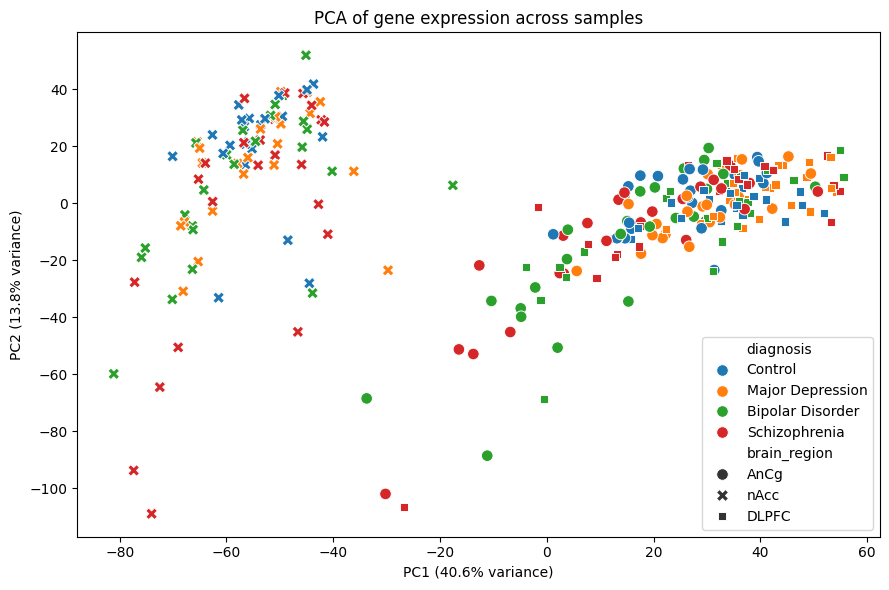

In [37]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="diagnosis",
    style="brain_region",
    s=70
)

plt.title("PCA of gene expression across samples")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")

plt.tight_layout()
plt.show()

The first two principal components explained 54.40% of the total variance in gene expression, with PC1 accounting for 40.63% and PC2 accounting for 13.77%. The PCA plot showed a noticeable separation between samples from different brain regions, particularly for the nucleus accumbens (nAcc). In contrast, samples from different diagnostic groups showed considerable overlap, with no clear clustering according to diagnosis. These findings suggest that brain region is an important source of variation in the dataset.

Important: This is an exploratory analysis. The absence of clear diagnostic clustering does not mean that there are no diagnosis-related differences in individual gene expression levels.

4.10 Investigate whether PCA patterns are associated with metadata variables

> In Step 4.9, we used PCA to visualize similarities and differences between samples. However, we also need to investigate why samples are clustering together.

For example, clustering might be associated with:
- Biological variables: diagnosis and brain region.
- Other sample characteristics: age and sex.
- Potential confounding factors: post-mortem interval (PMI) and brain pH.
This is important because the project instructions specifically ask us to investigate whether samples cluster according to biological variables or technical factors.



In [38]:
# Investigate correlations between PCA components and numerical metadata variables

numerical_variables = ["age", "PMI", "brain_pH"]

for variable in numerical_variables:
    print(f"\nCorrelation with {variable}:")

    for component in ["PC1", "PC2"]:
        correlation = pca_df[[component, variable]].corr(
            method="spearman"
        ).iloc[0, 1]

        print(f"{component}: {correlation:.3f}")


Correlation with age:
PC1: -0.109
PC2: -0.165

Correlation with PMI:
PC1: 0.091
PC2: -0.120

Correlation with brain_pH:
PC1: 0.196
PC2: 0.276


None of the numerical metadata variables shows a strong correlation with PC1 or PC2. Brain pH has the strongest association, particularly with PC2, but the correlation remains weak.

This suggests that age, PMI and brain pH do not appear to be major drivers of the sample distribution along the first two principal components.

Note that these are exploratory correlations, not tests of statistical significance. Also, three samples have missing brain pH values, which are automatically excluded from the corresponding correlation calculations.

4.11: Final assessment of preprocessing and quality control.

Check the final dataset dimensions and data quality

In [39]:
# Check the dimensions of the final filtered dataset

print("Number of genes after filtering:", filtered_count_matrix.shape[0])
print("Number of samples:", filtered_count_matrix.shape[1])

# Check for missing values
print("Missing values:", filtered_count_matrix.isna().sum().sum())

# Check for infinite values
print("Infinite values:", np.isinf(filtered_log_cpm_matrix).sum().sum())

# Check whether all expression values are non-negative
print("Negative values:", (filtered_count_matrix < 0).sum().sum())

Number of genes after filtering: 12296
Number of samples: 281
Missing values: 0
Infinite values: 0
Negative values: 0


Identify potential outliers in the PCA

In [40]:
# Calculate standardized PCA scores

pca_df["PC1_z"] = (
    pca_df["PC1"] - pca_df["PC1"].mean()
) / pca_df["PC1"].std()

pca_df["PC2_z"] = (
    pca_df["PC2"] - pca_df["PC2"].mean()
) / pca_df["PC2"].std()

# Identify samples with extreme PCA scores
potential_outliers = pca_df[
    (pca_df["PC1_z"].abs() > 3) |
    (pca_df["PC2_z"].abs() > 3)
]

# Display potential outliers
print("Number of potential outliers:", len(potential_outliers))

display(
    potential_outliers[
        ["description", "donor_id", "diagnosis",
         "brain_region", "PC1", "PC2"]
    ]
)

Number of potential outliers: 5


,description,donor_id,diagnosis,brain_region,PC1,PC2
111,SL6414,3452,Bipolar Disorder,AnCg,-11.152662,-88.548926
198,SL7390,4463,Schizophrenia,nAcc,-77.380809,-93.730659
231,SL7624,4404,Schizophrenia,AnCg,-30.210792,-101.963821
251,SL7704,4404,Schizophrenia,DLPFC,-26.727818,-106.548958
278,SL7857,4404,Schizophrenia,nAcc,-74.029716,-108.934576


Check sample alignment

In [41]:
# Check whether sample names match the metadata

print(
    "Sample order matches:",
    list(filtered_count_matrix.columns) ==
    list(metadata["description"])
)

Sample order matches: True


Investigate potential PCA outliers

In [42]:
# Identify the potential outlier sample IDs
outlier_ids = potential_outliers["description"].tolist()

# Calculate library sizes for all samples
library_sizes = count_matrix.sum(axis=0)

# Combine library sizes with sample metadata
sample_qc = metadata.copy()

sample_qc["library_size"] = (
    sample_qc["description"].map(library_sizes)
)

# Compare potential outliers with the full dataset
outlier_qc = sample_qc[
    sample_qc["description"].isin(outlier_ids)
]

display(
    outlier_qc[
        ["description", "donor_id", "diagnosis",
         "brain_region", "age", "PMI", "brain_pH",
         "library_size"]
    ]
)

,description,donor_id,diagnosis,brain_region,age,PMI,brain_pH,library_size
111,SL6414,3452,Bipolar Disorder,AnCg,69,28.25,6.65,29194754
198,SL7390,4463,Schizophrenia,nAcc,31,23.50,NaN,44508653
231,SL7624,4404,Schizophrenia,AnCg,50,25.70,6.64,31870485
251,SL7704,4404,Schizophrenia,DLPFC,50,25.70,6.64,32444701
278,SL7857,4404,Schizophrenia,nAcc,50,25.70,6.64,37315103


1. Library size

The five samples have between approximately 29 and 45 million reads. These values are not obviously extreme compared with the overall dataset (approximately 11.7–73.2 million reads).

Therefore, there is no clear indication of unusually low sequencing depth.

2. Age, PMI and brain pH
- The PMI values are relatively similar.
- The brain pH values are also similar for the samples with available measurements.
- SL7390 has a missing brain pH value, which is worth documenting, but this alone is not a reason to exclude it.
3. Donor-specific pattern

An interesting observation is that three outliers (SL7624, SL7704 and SL7857) belong to donor 4404.

They have identical age, PMI and brain pH values because they originate from the same donor, but represent three different brain regions.

This suggests that the separation in the PCA might reflect a donor-specific biological expression pattern rather than a technical problem affecting individual samples.
Conclusion
Based on the available quality indicators, we do not have sufficient evidence to remove any of these five samples. We should retain them for now and document them as potential PCA outliers.

TMM normalization

In [43]:

import numpy as np
import pandas as pd

# Use the filtered raw count matrix
counts_tmm = filtered_count_matrix.copy()

# Calculate library sizes for the filtered count matrix
library_sizes = counts_tmm.sum(axis=0).astype(float)

# Calculate CPM values for choosing the reference sample
cpm_for_reference = counts_tmm.div(library_sizes, axis=1) * 1_000_000

# Select the reference sample:
# the sample whose 75th percentile is closest to the mean
upper_quartiles = cpm_for_reference.quantile(0.75, axis=0)
reference_sample = (upper_quartiles - upper_quartiles.mean()).abs().idxmin()

print("Reference sample:", reference_sample)

# Calculate TMM normalization factors
tmm_factors = pd.Series(index=counts_tmm.columns, dtype=float)

reference_counts = counts_tmm[reference_sample].to_numpy(dtype=float)
reference_library_size = library_sizes[reference_sample]

for sample in counts_tmm.columns:

    sample_counts = counts_tmm[sample].to_numpy(dtype=float)
    sample_library_size = library_sizes[sample]

    # Exclude genes with zero counts in either sample
    valid = (sample_counts > 0) & (reference_counts > 0)

    y_sample = sample_counts[valid]
    y_reference = reference_counts[valid]

    # Calculate log fold changes (M-values)
    M = np.log2(
        (y_sample / sample_library_size) /
        (y_reference / reference_library_size)
    )

    # Calculate average expression (A-values)
    A = 0.5 * np.log2(
        (y_sample / sample_library_size) *
        (y_reference / reference_library_size)
    )

    # Calculate inverse variance weights
    weights = (
        (sample_library_size - y_sample) /
        (sample_library_size * y_sample)
        +
        (reference_library_size - y_reference) /
        (reference_library_size * y_reference)
    )

    # Remove genes with invalid values
    valid_weights = np.isfinite(weights) & (weights > 0)
    M = M[valid_weights]
    A = A[valid_weights]
    weights = weights[valid_weights]

    # Trim extreme M-values and A-values
    M_low, M_high = np.quantile(M, [0.30, 0.70])
    A_low, A_high = np.quantile(A, [0.05, 0.95])

    keep = (
        (M >= M_low) & (M <= M_high) &
        (A >= A_low) & (A <= A_high)
    )

    # Calculate the weighted mean of the retained M-values
    mean_M = np.average(M[keep], weights=1 / weights[keep])

    # Convert the weighted mean into a normalization factor
    tmm_factors[sample] = 2 ** mean_M

# Normalize factors so their geometric mean equals 1
tmm_factors = tmm_factors / np.exp(np.log(tmm_factors).mean())

# Display normalization factors
print("\nTMM normalization factors:")
display(tmm_factors.describe())


Reference sample: SL7809

TMM normalization factors:


,0
count,281.000000
mean,1.005847
std,0.098185
min,0.475984
25%,0.975097
50%,1.021085
75%,1.065077
max,1.239160


In [44]:

# Calculate effective library sizes
effective_library_sizes = library_sizes * tmm_factors

# Calculate TMM-normalized CPM values
tmm_cpm_matrix = (
    counts_tmm.div(effective_library_sizes, axis=1) * 1_000_000
)

# Apply log2 transformation
tmm_log_cpm_matrix = np.log2(tmm_cpm_matrix + 1)

# Display the first five rows
display(tmm_log_cpm_matrix.head())

print("Dimensions after TMM normalization:", tmm_log_cpm_matrix.shape)


,SL31501,SL31502,SL31503,SL31504,SL31505,SL31506,SL31507,SL31508,SL32225,SL32226,...,SL7849,SL7851,SL7852,SL7853,SL7854,SL7855,SL7856,SL7857,SL7858,SL8435
gene_id,,,,,,,,,,,,,,,,,,,,,
ENSG00000225972,1.100113,0.961602,1.094692,3.476708,9.427189,1.261274,1.308070,1.454128,1.064789,8.269938,...,1.158217,0.937305,1.395955,1.236289,1.516270,1.649249,1.537650,4.193711,1.700129,1.984345
ENSG00000225630,8.018284,8.665804,8.247094,9.011842,9.500449,9.176171,8.991987,9.172777,8.252165,7.967316,...,9.168169,8.866455,9.868484,9.190751,10.728091,9.407531,10.084114,13.403775,9.326438,10.090208
ENSG00000237973,7.678041,7.254894,7.201321,8.336631,11.043326,7.449370,8.233473,8.395618,7.732213,8.593459,...,7.153930,7.721313,7.471133,7.561052,7.805188,7.985238,8.001668,10.303011,8.224233,5.717951
ENSG00000229344,1.383137,1.714113,1.487342,3.601752,2.363808,1.784453,1.727014,1.947134,1.604693,1.748924,...,2.188583,2.053627,2.491326,2.150365,2.564266,2.615437,3.135846,5.156070,2.771106,2.540657
ENSG00000248527,9.682444,9.436795,9.701564,10.656360,11.667330,10.770893,10.442279,10.735774,9.815314,9.500565,...,10.502787,10.451504,10.902192,10.355303,10.786661,10.706962,11.243497,13.363094,10.661914,11.257128


Dimensions after TMM normalization: (12296, 281)


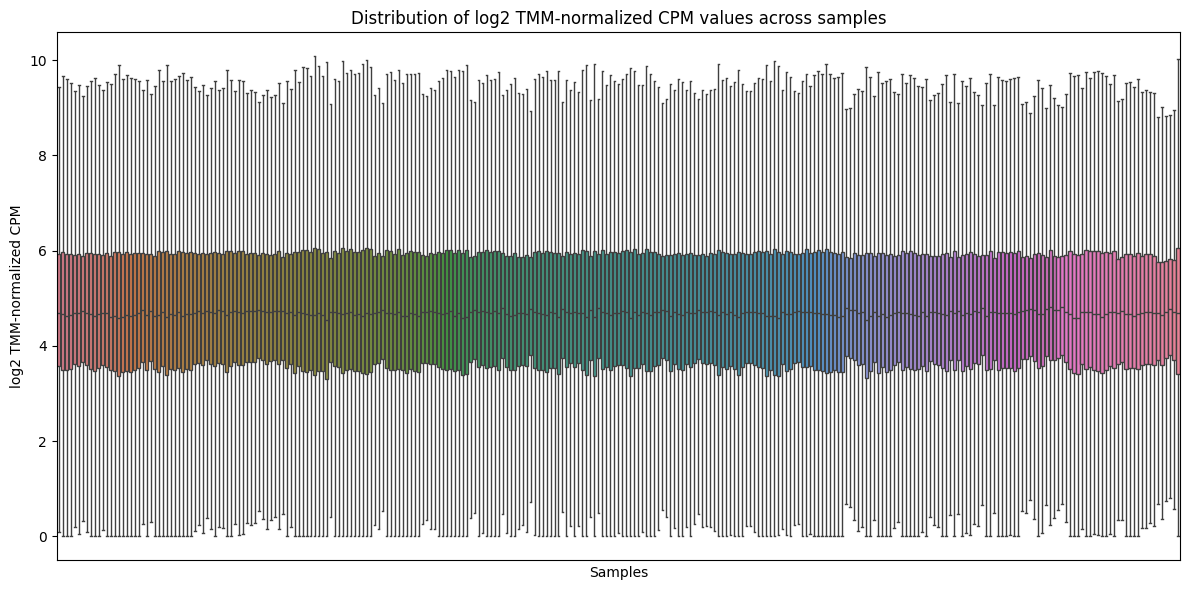

In [45]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=tmm_log_cpm_matrix,
    showfliers=False
)

plt.title("Distribution of log2 TMM-normalized CPM values across samples")
plt.xlabel("Samples")
plt.ylabel("log2 TMM-normalized CPM")

plt.xticks([])
plt.tight_layout()
plt.show()


In [46]:
from sklearn.decomposition import PCA

# Transpose the TMM-normalized expression matrix
# PCA expects samples as rows and genes as columns
expression_data_tmm = tmm_log_cpm_matrix.T

# Perform PCA
pca_tmm = PCA(n_components=2)
pca_results_tmm = pca_tmm.fit_transform(expression_data_tmm)

# Create a dataframe with the PCA results
pca_df_tmm = pd.DataFrame({
    "PC1": pca_results_tmm[:, 0],
    "PC2": pca_results_tmm[:, 1],
    "description": expression_data_tmm.index
})

# Add sample metadata
pca_df_tmm = pca_df_tmm.merge(
    metadata,
    on="description"
)

# Calculate explained variance
print(
    "Variance explained by PC1:",
    round(pca_tmm.explained_variance_ratio_[0] * 100, 2),
    "%"
)

print(
    "Variance explained by PC2:",
    round(pca_tmm.explained_variance_ratio_[1] * 100, 2),
    "%"
)

Variance explained by PC1: 43.31 %
Variance explained by PC2: 12.52 %


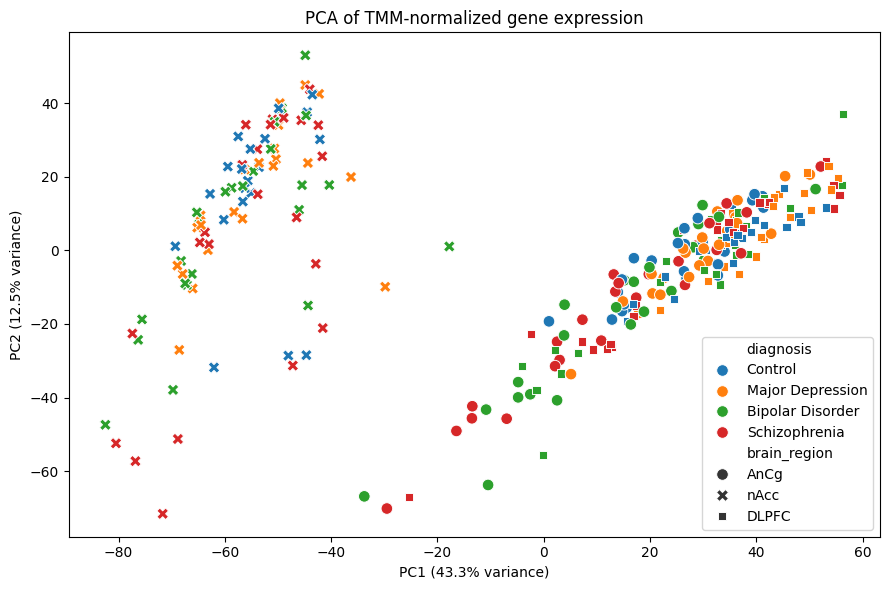

In [47]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df_tmm,
    x="PC1",
    y="PC2",
    hue="diagnosis",
    style="brain_region",
    s=70
)

plt.title("PCA of TMM-normalized gene expression")
plt.xlabel(
    f"PC1 ({pca_tmm.explained_variance_ratio_[0]*100:.1f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca_tmm.explained_variance_ratio_[1]*100:.1f}% variance)"
)

plt.tight_layout()
plt.show()

In [48]:
# Calculate standardized PCA scores after TMM normalization

pca_df_tmm["PC1_z"] = (
    pca_df_tmm["PC1"] - pca_df_tmm["PC1"].mean()
) / pca_df_tmm["PC1"].std()

pca_df_tmm["PC2_z"] = (
    pca_df_tmm["PC2"] - pca_df_tmm["PC2"].mean()
) / pca_df_tmm["PC2"].std()

# Identify samples with extreme PCA scores
potential_outliers_tmm = pca_df_tmm[
    (pca_df_tmm["PC1_z"].abs() > 3) |
    (pca_df_tmm["PC2_z"].abs() > 3)
]

# Display potential outliers
print("Number of potential outliers after TMM:",
      len(potential_outliers_tmm))

display(
    potential_outliers_tmm[
        ["description", "donor_id", "diagnosis",
         "brain_region", "PC1", "PC2"]
    ]
)

Number of potential outliers after TMM: 2


,description,donor_id,diagnosis,brain_region,PC1,PC2
231,SL7624,4404,Schizophrenia,AnCg,-29.516606,-70.178739
276,SL7855,4296,Schizophrenia,nAcc,-71.703519,-71.612800


In [49]:
# Identify the remaining potential outlier sample IDs
outlier_ids_tmm = potential_outliers_tmm["description"].tolist()

# Calculate library sizes for all samples
library_sizes = count_matrix.sum(axis=0)

# Create a copy of the metadata
sample_qc_tmm = metadata.copy()

# Add library size
sample_qc_tmm["library_size"] = (
    sample_qc_tmm["description"].map(library_sizes)
)

# Select the remaining potential outliers
outlier_qc_tmm = sample_qc_tmm[
    sample_qc_tmm["description"].isin(outlier_ids_tmm)
]

# Display their quality control information
display(
    outlier_qc_tmm[
        ["description", "donor_id", "diagnosis",
         "brain_region", "age", "PMI",
         "brain_pH", "library_size"]
    ]
)

# Compare with the full dataset
print("\nComparison with the full dataset:")

display(
    sample_qc_tmm[
        ["age", "PMI", "brain_pH", "library_size"]
    ].describe()
)

,description,donor_id,diagnosis,brain_region,age,PMI,brain_pH,library_size
231,SL7624,4404,Schizophrenia,AnCg,50,25.7,6.64,31870485
276,SL7855,4296,Schizophrenia,nAcc,36,11.2,6.82,30561833



Comparison with the full dataset:


,age,PMI,brain_pH,library_size
count,281.000000,281.000000,278.000000,2.810000e+02
mean,46.743772,22.667794,6.901475,4.208535e+07
std,12.707078,7.659093,0.178183,1.272908e+07
min,19.000000,6.250000,6.520000,1.168605e+07
25%,39.000000,17.200000,6.770000,3.322680e+07
50%,48.000000,24.000000,6.900000,4.086196e+07
75%,55.000000,27.500000,7.037500,5.075643e+07
max,72.000000,44.250000,7.390000,7.319786e+07


In [53]:
# Check the final dataset dimensions
print("Final number of genes:", filtered_count_matrix.shape[0])
print("Final number of samples:", filtered_count_matrix.shape[1])

# Check for missing values
print("Missing values:", filtered_count_matrix.isna().sum().sum())

# Check for infinite values
print("Infinite values:", np.isinf(filtered_log_cpm_matrix).sum().sum())

# Check for negative values
print("Negative values:", (filtered_count_matrix < 0).sum().sum())


# Check sample alignment between expression data and metadata
sample_ids = filtered_count_matrix.columns.tolist()
metadata_sample_ids = metadata["description"].tolist()

print(
    "Sample order matches:",
    sample_ids == metadata_sample_ids
)

# Check whether all samples are represented in the PCA results
print(
    "All samples included in PCA:",
    set(sample_ids) == set(pca_df["description"])
)

# Final dimensions
print("\nFinal dataset dimensions:")
print("Genes:", filtered_count_matrix.shape[0])
print("Samples:", filtered_count_matrix.shape[1])

Final number of genes: 12296
Final number of samples: 281
Missing values: 0
Infinite values: 0
Negative values: 0
Sample order matches: True
All samples included in PCA: True

Final dataset dimensions:
Genes: 12296
Samples: 281


In [54]:
# Save the filtered raw count matrix
filtered_count_matrix.to_csv("filtered_counts.csv")

# Save the TMM-normalized log2 CPM matrix
tmm_log_cpm_matrix.to_csv("TMM_normalized_logCPM.csv")

# Save the sample metadata
metadata.to_csv("sample_metadata.csv", index=False)

print("All preprocessed datasets have been saved successfully.")

All preprocessed datasets have been saved successfully.
